<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_class_practice/blob/main/Assignment_05_Decision_Tree_in_weather_dataset_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Libraries
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree
import matplotlib.pyplot as plt



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Lab-5/weather_dataset.csv")
df.head(5)

,outlook,temp.,humidity,windy,play
0,sunny,hot,high,False,no
1,sunny,hot,high,True,no
2,overcast,hot,high,False,yes
3,rainy,mild,high,False,yes
4,rainy,cool,normal,False,yes


In [ ]:
# -------------------------------
# Convert Categorical Data to Numeric
# -------------------------------

le = LabelEncoder()

for column in df.columns:
    df[column] = le.fit_transform(df[column])

print("\nEncoded Dataset:")
print(df.head())


Encoded Dataset:
   outlook  temp.  humidity  windy  play
0        2      1         0      0     0
1        2      1         0      1     0
2        0      1         0      0     1
3        1      2         0      0     1
4        1      0         1      0     1


In [ ]:

# Split Features and Target

X = df.drop('play', axis=1)   # Features
y = df['play']                # Target

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree Model

model = DecisionTreeClassifier(
    criterion='entropy',   # or 'gini'
    max_depth=3,
    random_state=42
)

# Train Model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

In [ ]:
# Evaluation
print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy:
0.6

Confusion Matrix:
[[1 1]
 [1 2]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.67      0.67      0.67         3

    accuracy                           0.60         5
   macro avg       0.58      0.58      0.58         5
weighted avg       0.60      0.60      0.60         5



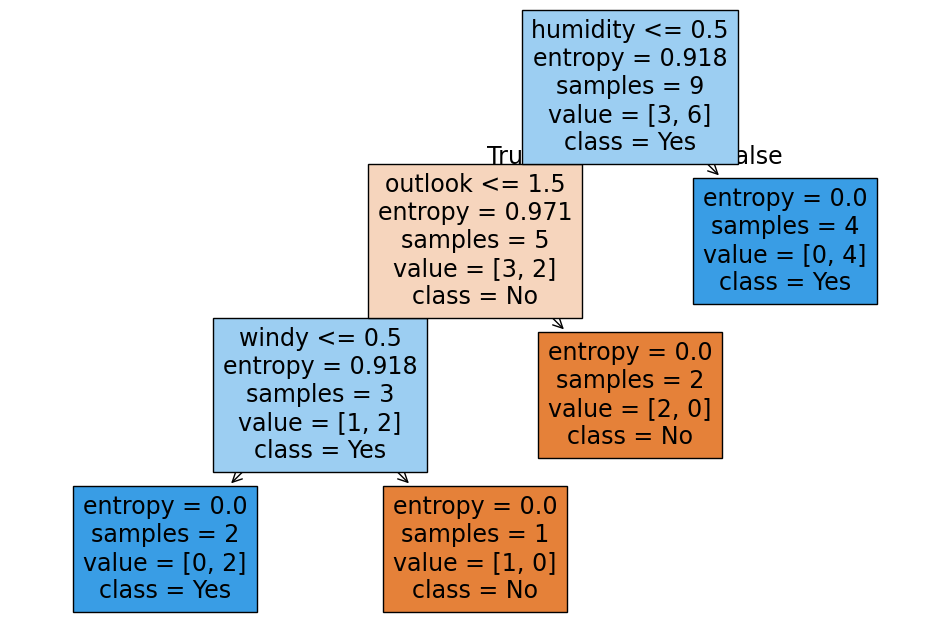

In [ ]:

# Visualize Decision Tree


plt.figure(figsize=(12,8))

tree.plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)

plt.show()